# Muay Thai Strike Classification Agent

This notebook tests the agent with video files and saves the results.


In [1]:
# Import necessary libraries
import json
import os
from datetime import datetime
from pathlib import Path

# Import the agent graph from the explicit implementation
from basic_agent_explicit import graph, llm
from langchain_core.messages import HumanMessage


In [2]:
# Load true labels for comparison
with open('data/combos/true_labels.json', 'r') as f:
    true_labels = json.load(f)

print("True labels loaded:")
for video_id, strikes in list(true_labels.items())[:5]:
    print(f"  Video {video_id}: {strikes}")


True labels loaded:
  Video 1: ['jab', 'cross', 'roundhouse']
  Video 2: ['jab', 'jab', 'cross', 'roundhouse']
  Video 3: ['jab', 'cross', 'lead_hook', 'lead_hook']
  Video 4: ['teep', 'roundhouse']
  Video 5: ['lead_uppercut', 'cross', 'lead_hook']


In [3]:
# Configuration
VIDEO_DIR = "data/combos"
RESULTS_DIR = "results"

# Create results directory if it doesn't exist
os.makedirs(RESULTS_DIR, exist_ok=True)

def save_result(video_id, video_path, predicted_strikes, true_strikes=None, full_response=None):
    """Save the classification result to a JSON file."""
    result = {
        "video_id": video_id,
        "video_path": video_path,
        "timestamp": datetime.now().isoformat(),
        "predicted_strikes": predicted_strikes,
        "true_strikes": true_strikes,
        "correct": predicted_strikes == true_strikes if true_strikes else None,
        "full_response": full_response
    }
    
    filename = f"{RESULTS_DIR}/result_{video_id}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"
    with open(filename, 'w') as f:
        json.dump(result, f, indent=2)
    
    print(f"\nResult saved to: {filename}")
    return result


## Test Single Video


In [4]:
# Test a single video
video_id = "1"
video_path = f"{VIDEO_DIR}/{video_id}.mov"

print(f"Analyzing video: {video_path}")
print("=" * 60)

# Get true labels if available
true_strikes = true_labels.get(video_id)
if true_strikes:
    print(f"True strikes: {true_strikes}")
    print("-" * 60)

# Invoke the agent
result = graph.invoke(
    {"messages": [HumanMessage(content=f"Classify the strikes in this video: {video_path}")]}
)

# Extract the response
agent_response = result["messages"][-1].content
print(f"\nAgent Response:")
print(agent_response)

# Try to parse JSON from response
import re
json_match = re.search(r'\[.*?\]', agent_response)
if json_match:
    try:
        predicted_strikes = json.loads(json_match.group())
        print(f"\nParsed strikes: {predicted_strikes}")
        
        # Compare with true labels
        if true_strikes:
            print(f"\nComparison:")
            print(f"  True:     {true_strikes}")
            print(f"  Predicted: {predicted_strikes}")
            print(f"  Match:    {predicted_strikes == true_strikes}")
        
        # Save result
        save_result(video_id, video_path, predicted_strikes, true_strikes, agent_response)
    except json.JSONDecodeError:
        print("\nCould not parse JSON from response")
        save_result(video_id, video_path, None, true_strikes, agent_response)
else:
    print("\nNo JSON array found in response")
    save_result(video_id, video_path, None, true_strikes, agent_response)


Analyzing video: data/combos/1.mov
True strikes: ['jab', 'cross', 'roundhouse']
------------------------------------------------------------
[DEBUG] analyze_video returned: ["teep"]...

Agent Response:
The video shows a single "teep" strike. The initial analysis identified this, and the pose data confirms the movement consistent with a teep.

Here's the breakdown:
- **Frames 0-10:** The fighter is in a ready stance, with the right leg slightly forward.
- **Frames 11-20:** The fighter begins to lift their right knee, indicating the start of a kick.
- **Frames 21-30:** The right leg extends forward, with the foot pushing out, characteristic of a teep. The hips also drive forward.
- **Frames 31-40:** The leg fully extends, and the foot makes contact (or simulates contact) with a target.
- **Frames 41-50:** The leg retracts, and the fighter returns to a more balanced stance.
- **Frames 51-80:** The fighter returns to a ready stance.

Therefore, the strike is a teep.

["teep"]

Parsed strik

## Test Multiple Videos

In [8]:
from time import sleep
# Test multiple videos
video_ids = ["1", "2", "3", "4", "5"]  # Adjust as needed

all_results = []

for video_id in video_ids:
    video_path = f"{VIDEO_DIR}/{video_id}.mov"
    
    if not os.path.exists(video_path):
        print(f"Skipping {video_id}: file not found")
        continue
    
    print(f"\n{'='*60}")
    print(f"Analyzing video {video_id}: {video_path}")
    print(f"{'='*60}")
    
    true_strikes = true_labels.get(video_id)
    if true_strikes:
        print(f"True strikes: {true_strikes}")
    
    try:
        # Invoke the agent
        result = graph.invoke(
            {"messages": [HumanMessage(content=f"Classify the strikes in this video: {video_path}")]}
        )
        
        agent_response = result["messages"][-1].content
        print(f"\nResponse: {agent_response[:200]}...")
        
        # Try to parse JSON
        import re
        json_match = re.search(r'\[.*?\]', agent_response)
        predicted_strikes = None
        
        if json_match:
            try:
                predicted_strikes = json.loads(json_match.group())
                print(f"Parsed: {predicted_strikes}")
                
                if true_strikes:
                    match = predicted_strikes == true_strikes
                    print(f"Match: {match}")
            except json.JSONDecodeError:
                print("Could not parse JSON")
        
        # Save result
        result_data = save_result(video_id, video_path, predicted_strikes, true_strikes, agent_response)
        all_results.append(result_data)
        
    except Exception as e:
        print(f"Error processing video {video_id}: {str(e)}")
        save_result(video_id, video_path, None, true_strikes, f"Error: {str(e)}")

    sleep(60) # sleep for 60 seconds to avoid rate limiting

print(f"\n\nCompleted {len(all_results)} videos")



Analyzing video 1: data/combos/1.mov
True strikes: ['jab', 'cross', 'roundhouse']
[DEBUG] analyze_video returned: ["teep"]...

Response: The video shows a single "teep" strike. The initial analysis by `analyze_video` correctly identified this. The pose data confirms the movement patterns consistent with a teep, with the right leg exten...
Parsed: ['teep']
Match: False

Result saved to: results/result_1_20251112_214921.json

Analyzing video 2: data/combos/2.mov
True strikes: ['jab', 'jab', 'cross', 'roundhouse']
[DEBUG] analyze_video returned: ["jab", "cross", "teep"]...

Response: [{'type': 'text', 'text': '["jab", "cross", "teep"]', 'extras': {'signature': 'CqMCAdHtim996BFMi8+7ib4130Rj5Al4Z0akuJOeliSk5ZaeZIzaGnVWErXOGb1hGajkYJsCU/3we9MHY5WzTerjeRW1vY6UQguNYnJTW0TAHlEyzQpU3YttGOjztZ+61WBW9EJ+TVSCDZOcFmN0//RFYxkGV+3QgLeugu6uSDKcG97dRDoJ9fXy4+5wyEaj568QlO7ip5jkP4h5nJAl3yGbZdZl5ce3ix8CwmbTqJXpKWF1i7iaqk5NwGDkER4uIYfJhTa8llbDHHS1eJRmZaTlIM+HJrLSL2G3ABPa9sR4ip+CKTYwEwTvF1FiuU/8WHTFMrGDLTZl

## Analyze Results


In [9]:
# Load and analyze saved results
import glob

result_files = glob.glob(f"{RESULTS_DIR}/result_*.json")

if result_files:
    # Get the most recent results
    result_files.sort(key=os.path.getmtime, reverse=True)
    
    print(f"Found {len(result_files)} result files")
    print("\nMost recent results:")
    
    for filepath in result_files[:10]:  # Show last 10
        with open(filepath, 'r') as f:
            result = json.load(f)
        
        video_id = result.get('video_id', 'unknown')
        predicted = result.get('predicted_strikes', 'N/A')
        true = result.get('true_strikes', 'N/A')
        correct = result.get('correct', 'N/A')
        
        print(f"\nVideo {video_id}:")
        print(f"  True:     {true}")
        print(f"  Predicted: {predicted}")
        print(f"  Correct:  {correct}")
else:
    print("No result files found")


Found 5 result files

Most recent results:

Video 5:
  True:     ['lead_uppercut', 'cross', 'lead_hook']
  Predicted: None
  Correct:  False

Video 4:
  True:     ['teep', 'roundhouse']
  Predicted: None
  Correct:  False

Video 3:
  True:     ['jab', 'cross', 'lead_hook', 'lead_hook']
  Predicted: None
  Correct:  False

Video 2:
  True:     ['jab', 'jab', 'cross', 'roundhouse']
  Predicted: None
  Correct:  False

Video 1:
  True:     ['jab', 'cross', 'roundhouse']
  Predicted: ['teep']
  Correct:  False


In [10]:
# Calculate accuracy
if result_files:
    results_with_labels = []
    
    for filepath in result_files:
        with open(filepath, 'r') as f:
            result = json.load(f)
        
        if result.get('true_strikes') and result.get('predicted_strikes'):
            results_with_labels.append(result)
    
    if results_with_labels:
        correct = sum(1 for r in results_with_labels if r.get('correct') == True)
        total = len(results_with_labels)
        accuracy = (correct / total) * 100 if total > 0 else 0
        
        print(f"\nAccuracy Summary:")
        print(f"  Correct: {correct}/{total}")
        print(f"  Accuracy: {accuracy:.1f}%")



Accuracy Summary:
  Correct: 0/1
  Accuracy: 0.0%


## Test with Pose Estimation Tool


Extracting pose data from: data/combos/1.mov
Extracting pose data...

Video info: {'fps': 30, 'total_frames': 81, 'video_path': 'data/combos/1.mov'}
Total frames: 81

Sample Landmark Data (First 3 frames):

Frame 0:
  left_wrist: x=0.347, y=0.331, z=0.118, vis=0.858
  right_wrist: x=0.301, y=0.286, z=-0.178, vis=0.980
  left_ankle: x=0.246, y=0.923, z=0.105, vis=0.451
  right_ankle: x=0.186, y=0.938, z=-0.041, vis=0.727
  left_shoulder: x=0.268, y=0.364, z=0.156, vis=1.000
  right_shoulder: x=0.206, y=0.313, z=-0.080, vis=1.000
  left_knee: x=0.266, y=0.752, z=0.060, vis=0.347
  right_knee: x=0.200, y=0.766, z=-0.096, vis=0.784

Frame 1:
  left_wrist: x=0.345, y=0.331, z=0.014, vis=0.850
  right_wrist: x=0.300, y=0.292, z=-0.238, vis=0.980
  left_ankle: x=0.247, y=0.923, z=0.114, vis=0.461
  right_ankle: x=0.187, y=0.936, z=-0.023, vis=0.731
  left_shoulder: x=0.267, y=0.364, z=0.127, vis=1.000
  right_shoulder: x=0.205, y=0.314, z=-0.095, vis=1.000
  left_knee: x=0.265, y=0.752, z=0.0

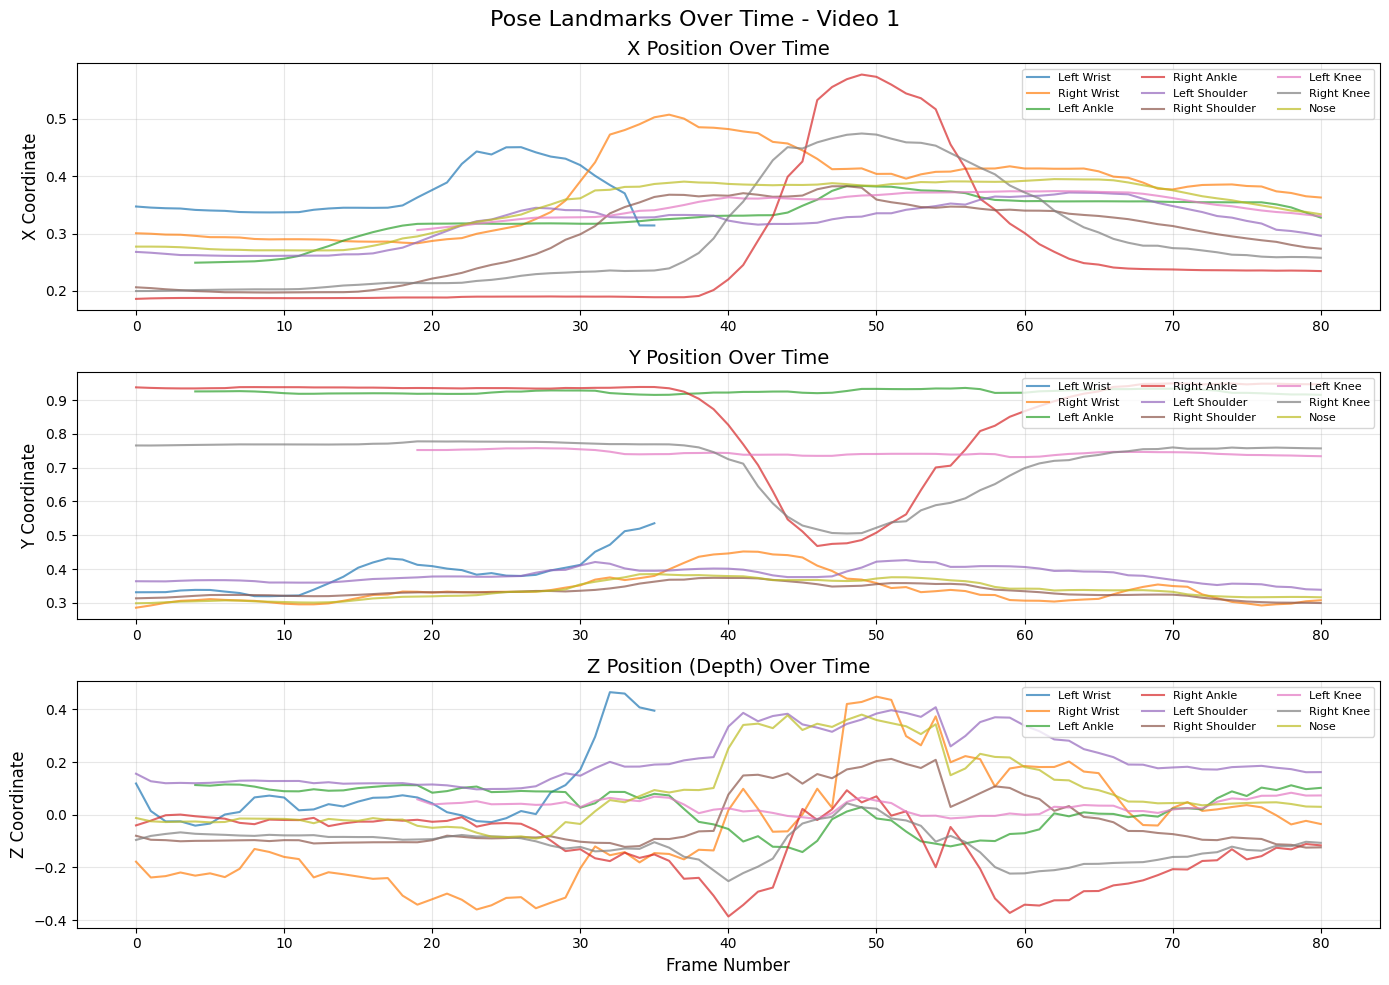


Creating 2D skeleton visualization for sample frames...


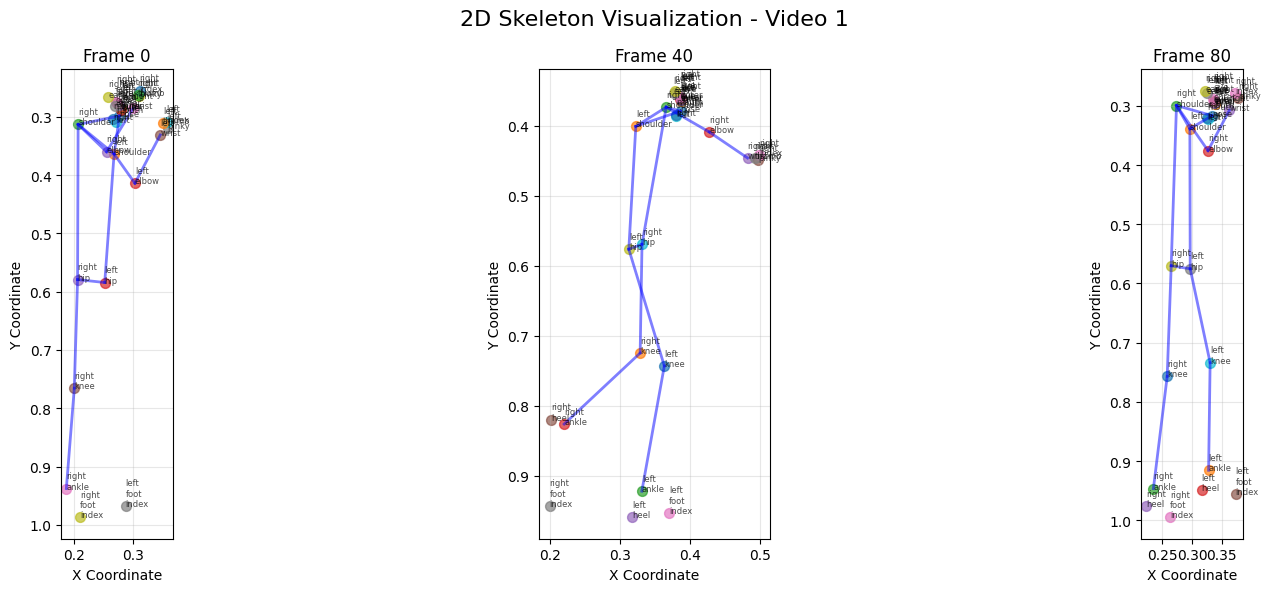


Total frames with pose detected: 81/81

Summary Statistics:
Left Wrist:
  X range: [0.314, 0.451], mean: 0.371
  Y range: [0.320, 0.535], mean: 0.387
  Samples: 36
Right Wrist:
  X range: [0.283, 0.507], mean: 0.376
  Y range: [0.286, 0.452], mean: 0.341
  Samples: 81
Left Ankle:
  X range: [0.249, 0.383], mean: 0.330
  Y range: [0.915, 0.936], mean: 0.924
  Samples: 77
Right Ankle:
  X range: [0.186, 0.577], mean: 0.265
  Y range: [0.468, 0.949], mean: 0.861
  Samples: 81
Left Shoulder:
  X range: [0.261, 0.372], mean: 0.318
  Y range: [0.339, 0.426], mean: 0.383
  Samples: 81
Right Shoulder:
  X range: [0.197, 0.383], mean: 0.293
  Y range: [0.299, 0.374], mean: 0.335
  Samples: 81
Left Knee:
  X range: [0.306, 0.374], mean: 0.351
  Y range: [0.731, 0.758], mean: 0.743
  Samples: 62
Right Knee:
  X range: [0.200, 0.475], mean: 0.290
  Y range: [0.505, 0.778], mean: 0.718
  Samples: 81
Nose:
  X range: [0.271, 0.395], mean: 0.348
  Y range: [0.299, 0.385], mean: 0.338
  Samples: 81



In [12]:
# Extract and visualize pose landmarks
import matplotlib.pyplot as plt
import numpy as np
import cv2
import mediapipe as mp

# Copy the extract_pose_data function (without @tool decorator)
def extract_pose_data_local(video_path: str) -> dict:
    """
    Extracts raw pose keypoint coordinates from a Muay Thai video using MediaPipe Pose.
    Returns frame-by-frame pose landmarks with coordinates (x, y, z, visibility).
    
    Args:
        video_path: Path to the video file to analyze
        
    Returns:
        A dictionary containing pose data with frame numbers, landmark names, and coordinates
    """
    # Verify video file exists
    if not os.path.exists(video_path):
        raise FileNotFoundError(f"Video file not found at {video_path}")
    
    # Initialize MediaPipe Pose
    mp_pose = mp.solutions.pose
    pose = mp_pose.Pose(
        static_image_mode=False,
        model_complexity=2,
        enable_segmentation=False,
        min_detection_confidence=0.5
    )
    
    # Open video file
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise ValueError(f"Could not open video file {video_path}")
    
    # Get video properties
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    # MediaPipe landmark names (33 landmarks)
    landmark_names = [
        "nose", "left_eye_inner", "left_eye", "left_eye_outer",
        "right_eye_inner", "right_eye", "right_eye_outer", "left_ear",
        "right_ear", "mouth_left", "mouth_right", "left_shoulder",
        "right_shoulder", "left_elbow", "right_elbow", "left_wrist",
        "right_wrist", "left_pinky", "right_pinky", "left_index",
        "right_index", "left_thumb", "right_thumb", "left_hip",
        "right_hip", "left_knee", "right_knee", "left_ankle",
        "right_ankle", "left_heel", "right_heel", "left_foot_index",
        "right_foot_index"
    ]
    
    # Store pose data for all frames
    pose_data = {
        "video_info": {
            "fps": fps,
            "total_frames": total_frames,
            "video_path": video_path
        },
        "frames": []
    }
    
    frame_number = 0
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        
        # Convert BGR to RGB (MediaPipe uses RGB)
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        # Process frame with MediaPipe
        results = pose.process(rgb_frame)
        
        # Extract landmarks for this frame
        frame_data = {
            "frame_number": frame_number,
            "landmarks": {}
        }
        
        if results.pose_landmarks:
            for idx, landmark in enumerate(results.pose_landmarks.landmark):
                landmark_name = landmark_names[idx] if idx < len(landmark_names) else f"landmark_{idx}"
                frame_data["landmarks"][landmark_name] = {
                    "x": float(landmark.x),
                    "y": float(landmark.y),
                    "z": float(landmark.z),
                    "visibility": float(landmark.visibility)
                }
        else:
            # No pose detected in this frame
            frame_data["landmarks"] = {}
        
        pose_data["frames"].append(frame_data)
        frame_number += 1
    
    # Release resources
    cap.release()
    pose.close()
    
    return pose_data

video_id = "1"
video_path = f"{VIDEO_DIR}/{video_id}.mov"

print(f"Extracting pose data from: {video_path}")
print("=" * 60)

# Extract pose data using the local function
print("Extracting pose data...")
pose_data = extract_pose_data_local(video_path)
print(f"\nVideo info: {pose_data['video_info']}")
print(f"Total frames: {len(pose_data['frames'])}")

# Display landmark information for first few frames
print("\n" + "=" * 60)
print("Sample Landmark Data (First 3 frames):")
print("=" * 60)

for frame_idx in range(min(3, len(pose_data['frames']))):
    frame = pose_data['frames'][frame_idx]
    print(f"\nFrame {frame['frame_number']}:")
    if frame['landmarks']:
        # Show a few key landmarks
        key_landmarks = ['left_wrist', 'right_wrist', 'left_ankle', 'right_ankle', 
                        'left_shoulder', 'right_shoulder', 'left_knee', 'right_knee']
        for landmark_name in key_landmarks:
            if landmark_name in frame['landmarks']:
                lm = frame['landmarks'][landmark_name]
                print(f"  {landmark_name}: x={lm['x']:.3f}, y={lm['y']:.3f}, z={lm['z']:.3f}, vis={lm['visibility']:.3f}")
    else:
        print("  No pose detected")

# Visualize pose landmarks over time for key body parts
print("\n" + "=" * 60)
print("Creating visualization of pose landmarks over time...")
print("=" * 60)

# Select key landmarks to track
landmarks_to_track = {
    'left_wrist': 'Left Wrist',
    'right_wrist': 'Right Wrist',
    'left_ankle': 'Left Ankle',
    'right_ankle': 'Right Ankle',
    'left_shoulder': 'Left Shoulder',
    'right_shoulder': 'Right Shoulder',
    'left_knee': 'Left Knee',
    'right_knee': 'Right Knee',
    'nose': 'Nose'
}

# Extract time series data for each landmark
frames_with_pose = [f for f in pose_data['frames'] if f['landmarks']]
if frames_with_pose:
    frame_numbers = [f['frame_number'] for f in frames_with_pose]
    
    # Create subplots for x, y, z coordinates
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))
    fig.suptitle(f'Pose Landmarks Over Time - Video {video_id}', fontsize=16)
    
    for landmark_name, display_name in landmarks_to_track.items():
        x_coords = []
        y_coords = []
        z_coords = []
        valid_frames = []
        
        for frame in frames_with_pose:
            if landmark_name in frame['landmarks']:
                lm = frame['landmarks'][landmark_name]
                if lm['visibility'] > 0.5:  # Only include visible landmarks
                    x_coords.append(lm['x'])
                    y_coords.append(lm['y'])
                    z_coords.append(lm['z'])
                    valid_frames.append(frame['frame_number'])
        
        if valid_frames:
            # Plot X coordinates
            axes[0].plot(valid_frames, x_coords, label=display_name, alpha=0.7, linewidth=1.5)
            # Plot Y coordinates
            axes[1].plot(valid_frames, y_coords, label=display_name, alpha=0.7, linewidth=1.5)
            # Plot Z coordinates
            axes[2].plot(valid_frames, z_coords, label=display_name, alpha=0.7, linewidth=1.5)
    
    axes[0].set_ylabel('X Coordinate', fontsize=12)
    axes[0].set_title('X Position Over Time', fontsize=14)
    axes[0].legend(loc='upper right', fontsize=8, ncol=3)
    axes[0].grid(True, alpha=0.3)
    
    axes[1].set_ylabel('Y Coordinate', fontsize=12)
    axes[1].set_title('Y Position Over Time', fontsize=14)
    axes[1].legend(loc='upper right', fontsize=8, ncol=3)
    axes[1].grid(True, alpha=0.3)
    
    axes[2].set_xlabel('Frame Number', fontsize=12)
    axes[2].set_ylabel('Z Coordinate', fontsize=12)
    axes[2].set_title('Z Position (Depth) Over Time', fontsize=14)
    axes[2].legend(loc='upper right', fontsize=8, ncol=3)
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Create a 2D skeleton visualization for a sample frame
    print("\nCreating 2D skeleton visualization for sample frames...")
    
    # MediaPipe pose connections (simplified skeleton)
    pose_connections = [
        ('left_shoulder', 'right_shoulder'),
        ('left_shoulder', 'left_elbow'),
        ('left_elbow', 'left_wrist'),
        ('right_shoulder', 'right_elbow'),
        ('right_elbow', 'right_wrist'),
        ('left_shoulder', 'left_hip'),
        ('right_shoulder', 'right_hip'),
        ('left_hip', 'right_hip'),
        ('left_hip', 'left_knee'),
        ('left_knee', 'left_ankle'),
        ('right_hip', 'right_knee'),
        ('right_knee', 'right_ankle'),
        ('left_shoulder', 'nose'),
        ('right_shoulder', 'nose'),
    ]
    
    # Show skeleton for first, middle, and last frame with pose
    sample_frames = [0, len(frames_with_pose)//2, len(frames_with_pose)-1]
    sample_frames = [f for f in sample_frames if f < len(frames_with_pose)]
    
    fig, axes = plt.subplots(1, len(sample_frames), figsize=(6*len(sample_frames), 6))
    if len(sample_frames) == 1:
        axes = [axes]
    
    fig.suptitle(f'2D Skeleton Visualization - Video {video_id}', fontsize=16)
    
    for idx, frame_idx in enumerate(sample_frames):
        frame = frames_with_pose[frame_idx]
        ax = axes[idx]
        
        # Plot landmarks
        for landmark_name, landmark_data in frame['landmarks'].items():
            if landmark_data['visibility'] > 0.5:
                ax.scatter(landmark_data['x'], landmark_data['y'], 
                          s=50, alpha=0.7, label=landmark_name if idx == 0 else "")
                ax.text(landmark_data['x'], landmark_data['y'], 
                       landmark_name.replace('_', '\n'), fontsize=6, alpha=0.7)
        
        # Draw connections
        for start_name, end_name in pose_connections:
            if start_name in frame['landmarks'] and end_name in frame['landmarks']:
                start = frame['landmarks'][start_name]
                end = frame['landmarks'][end_name]
                if start['visibility'] > 0.5 and end['visibility'] > 0.5:
                    ax.plot([start['x'], end['x']], [start['y'], end['y']], 
                           'b-', alpha=0.5, linewidth=2)
        
        ax.set_xlabel('X Coordinate', fontsize=10)
        ax.set_ylabel('Y Coordinate', fontsize=10)
        ax.set_title(f'Frame {frame["frame_number"]}', fontsize=12)
        ax.invert_yaxis()  # Invert Y axis to match image coordinates
        ax.grid(True, alpha=0.3)
        ax.set_aspect('equal', adjustable='box')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nTotal frames with pose detected: {len(frames_with_pose)}/{len(pose_data['frames'])}")
    
    # Show summary statistics
    print("\n" + "=" * 60)
    print("Summary Statistics:")
    print("=" * 60)
    for landmark_name, display_name in landmarks_to_track.items():
        all_x = []
        all_y = []
        for frame in frames_with_pose:
            if landmark_name in frame['landmarks']:
                lm = frame['landmarks'][landmark_name]
                if lm['visibility'] > 0.5:
                    all_x.append(lm['x'])
                    all_y.append(lm['y'])
        
        if all_x:
            print(f"{display_name}:")
            print(f"  X range: [{min(all_x):.3f}, {max(all_x):.3f}], mean: {np.mean(all_x):.3f}")
            print(f"  Y range: [{min(all_y):.3f}, {max(all_y):.3f}], mean: {np.mean(all_y):.3f}")
            print(f"  Samples: {len(all_x)}")
else:
    print("No frames with pose detected!")

# Show what will be sent to the model (sample of JSON)
print("\n" + "=" * 60)
print("Sample of JSON data that will be sent to the model:")
print("=" * 60)
sample_json = {
    "video_info": pose_data['video_info'],
    "frames": pose_data['frames'][:2]  # First 2 frames as sample
}
pose_data_str = json.dumps(sample_json, indent=2)
print(pose_data_str[:1000] + "...")
print(f"\n(Full JSON has {len(pose_data['frames'])} frames)")

# Convert to JSON string format (as the tool would return it)
pose_data_json_str = json.dumps(pose_data, indent=2)
print(f"\nFull JSON string length: {len(pose_data_json_str)} characters")
